## delete everything the setup created colab

In [ ]:
import os
import shutil
from pathlib import Path

BASE_DIR = Path("/content")

# Never touch a mounted Google Drive: deleting it removes your real Drive files.
KEEP = {"drive"}

# Leave the working directory first, since /content/notebooks gets deleted.
os.chdir(BASE_DIR)

for item in BASE_DIR.iterdir():
    if item.name in KEEP:
        print("Skipped:", item)
        continue

    try:
        if item.is_symlink() or item.is_file():
            item.unlink()
            print("Deleted file:", item)
        elif item.is_dir():
            shutil.rmtree(item, ignore_errors=True)
            print("Deleted folder:", item)
    except Exception as e:
        print(f"Failed to delete {item}: {e}")

print("Cleanup complete.")

## this to upload data to colab and install requerments colab

In [ ]:
import os
import re
import shutil
import subprocess
import sys
import urllib.request
import zipfile
from pathlib import Path

# ---------- Configuration ----------
REQ_URL = (
    "https://raw.githubusercontent.com/"
    "oelaimar/NeuroVision-AI/master/requirements.txt"
)
REPO_ZIP_URL = (
    "https://codeload.github.com/"
    "oelaimar/NeuroVision-AI/zip/refs/heads/master"
)

BASE_DIR = Path("/content")
REQ_IN = BASE_DIR / "requirements.txt"
REQ_OUT = BASE_DIR / "requirements_filtered.txt"

REPO_ZIP = BASE_DIR / "repo.zip"
REPO_TMP = BASE_DIR / "tmp_repo"
SRC_DIR = BASE_DIR / "src"

FILE_ID = "1p7R-87Embk8yJq35tkcJDpJ0f72m8-bs"
ZIP_PATH = BASE_DIR / "data.zip"
TMP_DIR = BASE_DIR / "tmp_unzip"
RAW_DIR = BASE_DIR / "data/raw"
WORK_DIR = BASE_DIR / "notebooks"

CLASSES = {"glioma", "meningioma", "notumor", "pituitary"}

SKIP = {
    "numpy", "pandas", "scipy", "matplotlib", "scikit-learn",
    "pillow", "torch", "torchvision", "tensorflow",
    "opencv-python",
}


# ---------- Helpers ----------
def run(command):
    subprocess.check_call(command)


def has_classes(path):
    """Check that every expected class contains at least one image."""
    path = Path(path)

    if not path.is_dir():
        return False

    for class_name in CLASSES:
        class_dir = path / class_name

        if not class_dir.is_dir():
            return False

        if not any(
            file.is_file()
            for file in class_dir.rglob("*")
            if file.suffix.lower() in {
                ".jpg", ".jpeg", ".png", ".bmp", ".webp"
            }
        ):
            return False

    return True


def safe_extract(archive, destination):
    """Reject ZIP entries that would extract outside destination."""
    destination = Path(destination).resolve()

    for member in archive.infolist():
        target = (destination / member.filename).resolve()

        if os.path.commonpath([str(destination), str(target)]) != str(destination):
            raise ValueError(
                f"Unsafe path in ZIP archive: {member.filename}"
            )

    archive.extractall(destination)


def install_requirements():
    print("Downloading requirements...")

    with urllib.request.urlopen(REQ_URL, timeout=30) as response:
        REQ_IN.write_bytes(response.read())

    # Normalize package names for comparison.
    skipped = {
        re.sub(r"[-_.]+", "-", name).lower()
        for name in SKIP
    }

    with REQ_IN.open(encoding="utf-8") as source, \
            REQ_OUT.open("w", encoding="utf-8") as output:

        for original_line in source:
            line = original_line.strip()

            if not line or line.startswith("#"):
                continue

            # This simple filter intentionally excludes pip options
            # and nested requirements; review these if your file uses them.
            if line.startswith("-"):
                print(f"Skipping pip directive: {line}")
                continue

            # Handles standard package specs and extras, such as
            # package>=1.0 and package[extra]>=1.0.
            match = re.match(r"^([A-Za-z0-9_.-]+)", line)

            if not match:
                print(f"Review unsupported requirement: {line}")
                continue

            name = re.sub(r"[-_.]+", "-", match.group(1)).lower()

            if name not in skipped:
                output.write(line + "\n")

    if REQ_OUT.stat().st_size:
        run([
            sys.executable, "-m", "pip", "install",
            "-r", str(REQ_OUT)
        ])

    print("Requirements processed.")


def fetch_src():
    """Download the repo ZIP and copy its src/ folder to /content/src."""
    print("Fetching src folder...")

    shutil.rmtree(REPO_TMP, ignore_errors=True)
    REPO_TMP.mkdir(parents=True, exist_ok=True)

    try:
        with urllib.request.urlopen(REPO_ZIP_URL, timeout=60) as response:
            REPO_ZIP.write_bytes(response.read())

        with zipfile.ZipFile(REPO_ZIP) as archive:
            safe_extract(archive, REPO_TMP)

        # The ZIP contains a single top-level folder: NeuroVision-AI-master/
        repo_root = next(
            (p for p in REPO_TMP.iterdir() if p.is_dir()),
            None,
        )

        if repo_root is None or not (repo_root / "src").is_dir():
            raise FileNotFoundError("No src/ folder found in the repository.")

        # Always replace so repo updates are picked up on re-run.
        shutil.rmtree(SRC_DIR, ignore_errors=True)
        shutil.copytree(repo_root / "src", SRC_DIR)

    finally:
        shutil.rmtree(REPO_TMP, ignore_errors=True)
        REPO_ZIP.unlink(missing_ok=True)

    # Make `import src...` work from notebooks.
    if str(BASE_DIR) not in sys.path:
        sys.path.insert(0, str(BASE_DIR))

    print(f"src ready: {SRC_DIR}")


def download_dataset():
    import gdown

    if ZIP_PATH.exists():
        try:
            with zipfile.ZipFile(ZIP_PATH) as archive:
                if archive.testzip() is None:
                    print("Using existing valid ZIP.")
                    return
        except zipfile.BadZipFile:
            pass

        print("Existing ZIP is invalid. Downloading again.")
        ZIP_PATH.unlink(missing_ok=True)

    result = gdown.download(
        id=FILE_ID,
        output=str(ZIP_PATH),
        quiet=False,
    )

    if not result or not ZIP_PATH.is_file():
        raise RuntimeError("Dataset download failed.")

    with zipfile.ZipFile(ZIP_PATH) as archive:
        bad_file = archive.testzip()
        if bad_file is not None:
            ZIP_PATH.unlink(missing_ok=True)
            raise RuntimeError(f"Corrupted ZIP member: {bad_file}")


def prepare_dataset():
    if has_classes(RAW_DIR):
        print(f"Dataset already ready: {RAW_DIR}")
        return

    # Do not keep a partially prepared dataset.
    shutil.rmtree(RAW_DIR, ignore_errors=True)
    shutil.rmtree(TMP_DIR, ignore_errors=True)
    TMP_DIR.mkdir(parents=True, exist_ok=True)

    try:
        download_dataset()

        with zipfile.ZipFile(ZIP_PATH) as archive:
            safe_extract(archive, TMP_DIR)

        # Find the directory containing all four class folders.
        source_dir = next(
            (
                Path(root)
                for root, dirs, _ in os.walk(TMP_DIR)
                if CLASSES.issubset(set(dirs))
            ),
            None,
        )

        if source_dir is None or not has_classes(source_dir):
            raise FileNotFoundError(
                "Could not find all four valid class folders "
                "with images in the ZIP."
            )

        RAW_DIR.parent.mkdir(parents=True, exist_ok=True)
        shutil.move(str(source_dir), str(RAW_DIR))

        if not has_classes(RAW_DIR):
            raise RuntimeError("Dataset validation failed after moving.")

        print(f"Dataset ready: {RAW_DIR}")

    finally:
        shutil.rmtree(TMP_DIR, ignore_errors=True)


def setup():
    install_requirements()
    fetch_src()

    # Install gdown only when it is actually needed.
    if not has_classes(RAW_DIR):
        try:
            import gdown  # noqa: F401
        except ImportError:
            run([
                sys.executable, "-m", "pip",
                "install", "gdown"
            ])

        prepare_dataset()

    WORK_DIR.mkdir(parents=True, exist_ok=True)
    os.chdir(WORK_DIR)

    print(f"Working directory: {Path.cwd()}")
    print("Setup complete.")


setup()

## delete everything the setup created kaggle

In [ ]:
import os
import shutil
from pathlib import Path

# Kaggle: /kaggle/working is the only persistent, writable output dir.
# /kaggle/input is read-only (datasets/models), so it is never touched.
BASE_DIR = Path("/kaggle/working")

# Names to keep (add e.g. "best_model.keras" if you want to preserve outputs)
KEEP = set()

# Leave the directory first, in case the cwd is a folder about to be deleted.
os.chdir(BASE_DIR)

for item in BASE_DIR.iterdir():
    if item.name in KEEP:
        print("Skipped:", item)
        continue

    try:
        if item.is_symlink() or item.is_file():
            item.unlink()
            print("Deleted file:", item)
        elif item.is_dir():
            shutil.rmtree(item, ignore_errors=True)
            print("Deleted folder:", item)
    except Exception as e:
        print(f"Failed to delete {item}: {e}")

print("Cleanup complete.")

## this to upload data to kaggle and install requerments

In [2]:
import os
import re
import shutil
import subprocess
import sys
import urllib.request
import zipfile
from pathlib import Path

# ---------- Configuration ----------
REQ_URL = (
    "https://raw.githubusercontent.com/"
    "oelaimar/NeuroVision-AI/master/requirements.txt"
)
REPO_ZIP_URL = (
    "https://codeload.github.com/"
    "oelaimar/NeuroVision-AI/zip/refs/heads/master"
)

# Kaggle: /kaggle/working is the only writable, persistent output dir.
BASE_DIR = Path("/kaggle/working")
REQ_IN = BASE_DIR / "requirements.txt"
REQ_OUT = BASE_DIR / "requirements_filtered.txt"

REPO_ZIP = BASE_DIR / "repo.zip"
REPO_TMP = BASE_DIR / "tmp_repo"
SRC_DIR = BASE_DIR / "src"

FILE_ID = "1p7R-87Embk8yJq35tkcJDpJ0f72m8-bs"
ZIP_PATH = BASE_DIR / "data.zip"
TMP_DIR = BASE_DIR / "tmp_unzip"
RAW_DIR = BASE_DIR / "data/raw"
WORK_DIR = BASE_DIR / "notebooks"

CLASSES = {"glioma", "meningioma", "notumor", "pituitary"}

SKIP = {
    "numpy", "pandas", "scipy", "matplotlib", "scikit-learn",
    "pillow", "torch", "torchvision", "tensorflow",
    "opencv-python",
}


# ---------- Helpers ----------
def run(command):
    subprocess.check_call(command)


def has_classes(path):
    """Check that every expected class contains at least one image."""
    path = Path(path)

    if not path.is_dir():
        return False

    for class_name in CLASSES:
        class_dir = path / class_name

        if not class_dir.is_dir():
            return False

        if not any(
            file.is_file()
            for file in class_dir.rglob("*")
            if file.suffix.lower() in {
                ".jpg", ".jpeg", ".png", ".bmp", ".webp"
            }
        ):
            return False

    return True


def safe_extract(archive, destination):
    """Reject ZIP entries that would extract outside destination."""
    destination = Path(destination).resolve()

    for member in archive.infolist():
        target = (destination / member.filename).resolve()

        if os.path.commonpath([str(destination), str(target)]) != str(destination):
            raise ValueError(
                f"Unsafe path in ZIP archive: {member.filename}"
            )

    archive.extractall(destination)


def install_requirements():
    print("Downloading requirements...")

    with urllib.request.urlopen(REQ_URL, timeout=30) as response:
        REQ_IN.write_bytes(response.read())

    # Normalize package names for comparison.
    skipped = {
        re.sub(r"[-_.]+", "-", name).lower()
        for name in SKIP
    }

    with REQ_IN.open(encoding="utf-8") as source, \
            REQ_OUT.open("w", encoding="utf-8") as output:

        for original_line in source:
            line = original_line.strip()

            if not line or line.startswith("#"):
                continue

            # This simple filter intentionally excludes pip options
            # and nested requirements; review these if your file uses them.
            if line.startswith("-"):
                print(f"Skipping pip directive: {line}")
                continue

            match = re.match(r"^([A-Za-z0-9_.-]+)", line)

            if not match:
                print(f"Review unsupported requirement: {line}")
                continue

            name = re.sub(r"[-_.]+", "-", match.group(1)).lower()

            if name not in skipped:
                output.write(line + "\n")

    if REQ_OUT.stat().st_size:
        run([
            sys.executable, "-m", "pip", "install",
            "-r", str(REQ_OUT)
        ])

    print("Requirements processed.")


def fetch_src():
    """Download the repo ZIP and copy its src/ folder to /kaggle/working/src."""
    print("Fetching src folder...")

    shutil.rmtree(REPO_TMP, ignore_errors=True)
    REPO_TMP.mkdir(parents=True, exist_ok=True)

    try:
        with urllib.request.urlopen(REPO_ZIP_URL, timeout=60) as response:
            REPO_ZIP.write_bytes(response.read())

        with zipfile.ZipFile(REPO_ZIP) as archive:
            safe_extract(archive, REPO_TMP)

        # The ZIP contains a single top-level folder: NeuroVision-AI-master/
        repo_root = next(
            (p for p in REPO_TMP.iterdir() if p.is_dir()),
            None,
        )

        if repo_root is None or not (repo_root / "src").is_dir():
            raise FileNotFoundError("No src/ folder found in the repository.")

        # Always replace so repo updates are picked up on re-run.
        shutil.rmtree(SRC_DIR, ignore_errors=True)
        shutil.copytree(repo_root / "src", SRC_DIR)

    finally:
        shutil.rmtree(REPO_TMP, ignore_errors=True)
        REPO_ZIP.unlink(missing_ok=True)

    # Make `import src...` work from notebooks.
    if str(BASE_DIR) not in sys.path:
        sys.path.insert(0, str(BASE_DIR))

    print(f"src ready: {SRC_DIR}")


def download_dataset():
    import gdown

    if ZIP_PATH.exists():
        try:
            with zipfile.ZipFile(ZIP_PATH) as archive:
                if archive.testzip() is None:
                    print("Using existing valid ZIP.")
                    return
        except zipfile.BadZipFile:
            pass

        print("Existing ZIP is invalid. Downloading again.")
        ZIP_PATH.unlink(missing_ok=True)

    result = gdown.download(
        id=FILE_ID,
        output=str(ZIP_PATH),
        quiet=False,
    )

    if not result or not ZIP_PATH.is_file():
        raise RuntimeError("Dataset download failed.")

    with zipfile.ZipFile(ZIP_PATH) as archive:
        bad_file = archive.testzip()
        if bad_file is not None:
            ZIP_PATH.unlink(missing_ok=True)
            raise RuntimeError(f"Corrupted ZIP member: {bad_file}")


def prepare_dataset():
    if has_classes(RAW_DIR):
        print(f"Dataset already ready: {RAW_DIR}")
        return

    # Do not keep a partially prepared dataset.
    shutil.rmtree(RAW_DIR, ignore_errors=True)
    shutil.rmtree(TMP_DIR, ignore_errors=True)
    TMP_DIR.mkdir(parents=True, exist_ok=True)

    try:
        download_dataset()

        with zipfile.ZipFile(ZIP_PATH) as archive:
            safe_extract(archive, TMP_DIR)

        # Find the directory containing all four class folders.
        source_dir = next(
            (
                Path(root)
                for root, dirs, _ in os.walk(TMP_DIR)
                if CLASSES.issubset(set(dirs))
            ),
            None,
        )

        if source_dir is None or not has_classes(source_dir):
            raise FileNotFoundError(
                "Could not find all four valid class folders "
                "with images in the ZIP."
            )

        RAW_DIR.parent.mkdir(parents=True, exist_ok=True)
        shutil.move(str(source_dir), str(RAW_DIR))

        if not has_classes(RAW_DIR):
            raise RuntimeError("Dataset validation failed after moving.")

        print(f"Dataset ready: {RAW_DIR}")

    finally:
        shutil.rmtree(TMP_DIR, ignore_errors=True)


def setup():
    install_requirements()
    fetch_src()

    # Install gdown only when it is actually needed.
    if not has_classes(RAW_DIR):
        try:
            import gdown  # noqa: F401
        except ImportError:
            run([
                sys.executable, "-m", "pip",
                "install", "gdown"
            ])

        prepare_dataset()

    WORK_DIR.mkdir(parents=True, exist_ok=True)
    os.chdir(WORK_DIR)

    print(f"Working directory: {Path.cwd()}")
    print("Setup complete.")


setup()
## check if all data are images

INFO: pip is looking at multiple versions of notebook to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 42.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.2/123.2 kB 757.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.2/110.2 kB 739.6 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 76.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 109.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 99.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 947.5/947.5 kB 43.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.6/394.6 kB 20.8 MB/s eta 0:00:00
  Attempting uninstall: jupyter-client
    Found existing installation: jupyter_client 7.4.9
    Uninstalling jupyter_client-7.4.9:
      Successfully uninstalled jupyter_client-7.4.9
  Attempting uninstall: ipykerne

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires ipykernel==6.17.1, but you have ipykernel 7.4.0 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.20.0, but you have jupyter-server 2.21.1 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
jupyter-kernel-gateway 2.5.2 requires jupyter_client<8.0,>=5.2.0, but you have jupyter-client 8.10.0 which is incompatible.
jupyter-kernel-gateway 2.5.2 requires notebook<7.0,>=5.7.6, but you have notebook 7.6.3 which is incompatible.


Requirements processed.
Fetching src folder...
src ready: /kaggle/working/src


Downloading...
From (original): https://drive.google.com/uc?id=1p7R-87Embk8yJq35tkcJDpJ0f72m8-bs
From (redirected): https://drive.google.com/uc?id=1p7R-87Embk8yJq35tkcJDpJ0f72m8-bs&confirm=t&uuid=dbef541a-34c6-4e82-b279-73fcd4c094c9
To: /kaggle/working/data.zip
100%|██████████| 156M/156M [00:03<00:00, 46.1MB/s] 


Dataset ready: /kaggle/working/data/raw
Working directory: /kaggle/working/notebooks
Setup complete.


In [3]:
import os

image_extensions = {".jpg", ".jpeg", ".png"}
classes = ["glioma", "meningioma", "notumor", "pituitary"]

non_image = []
for c in classes:
    folder_path = os.path.join(RAW_DIR, c)
    for f in os.listdir(folder_path):
        full = os.path.join(folder_path, f)
        if os.path.isfile(full) and os.path.splitext(f)[1].lower() not in image_extensions:
            non_image.append(full)

print(len(non_image))

0


## import libraries and functions

In [58]:
import os
import sys

# run from the project root so "src" and "data/" paths resolve
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay



from src.pipeline import load_dataset_cached, get_datasets, get_test_ds
from src.balance import class_distribution

RAW_DIR = os.path.join("data", "raw")
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20
SEED = 42
VAL_SPLIT = 0.15
TEST_SPLIT = 0.15

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.20.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Load Dataset
OpenCV decode + resize once, then reuse the `.npz` cache.

In [59]:
X, y = load_dataset_cached(RAW_DIR, CLASSES, target_size=IMG_SIZE, seed=SEED)
print(X.shape, X.dtype, y.shape, y.dtype)

(7023, 224, 224, 3) uint8 (7023,) int64


## 3. Class Balance Analysis


Class distribution (full dataset)
  glioma         1621   23.1%  ################################
  meningioma     1645   23.4%  ################################
  notumor        2000   28.5%  ########################################
  pituitary      1757   25.0%  ###################################
  imbalance ratio (max/min) = 1.23 -> balanced enough: no rebalancing needed


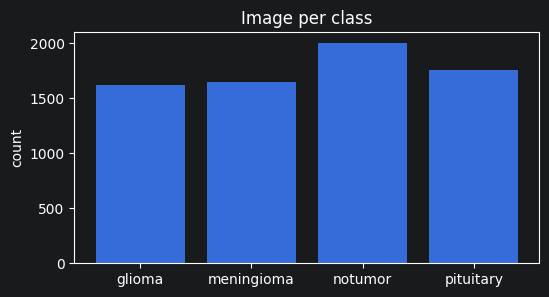

In [60]:
counts = class_distribution(y, CLASSES, "(full dataset)")

plt.figure(figsize=(6, 3))
plt.bar(CLASSES, counts)
plt.title("Image per class")
plt.ylabel("count")
plt.show()

## 4. Build tf.data Pipelines
Stratified train/val split + rebalancing strategy (`auto`, `none`, `class_weight`, `augment`).

In [61]:
train_ds, val_ds, class_weight = get_datasets(
    RAW_DIR, CLASSES,
    batch_size=BATCH_SIZE,
    target_size=IMG_SIZE,
    val_split=VAL_SPLIT,
    test_split=TEST_SPLIT,
    seed=SEED,
    strategy="auto"
)

def to_one_hot(ds):
    ds = ds.map(lambda x, y: (x, tf.one_hot(y, len(CLASSES))), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_oh = to_one_hot(train_ds)
val_oh = to_one_hot(val_ds)

Duplicates removed: 426 (kept 6597)

Class distribution (train)
  glioma         1134   24.5%  #####################################
  meningioma     1073   23.2%  ###################################
  notumor        1196   25.9%  #######################################
  pituitary      1218   26.4%  ########################################
  imbalance ratio (max/min) = 1.14 -> balanced enough: no rebalancing needed

Class distribution (val)
  glioma          243   24.6%  #####################################
  meningioma      229   23.2%  ###################################
  notumor         255   25.8%  #######################################
  pituitary       261   26.4%  ########################################
  imbalance ratio (max/min) = 1.14 -> balanced enough: no rebalancing needed

Class distribution (test, counts only)
  glioma          243   24.6%  #####################################
  meningioma      229   23.2%  ###################################
  notumor         255 

## 5. Sanity Check (one batch)

In [62]:
for xb, yb in train_ds.take(1):
    print(xb.shape, xb.dtype, yb.shape)
    print("pixel range:", float(tf.reduce_min(xb)), "-", float(tf.reduce_max(xb)))

(32, 224, 224, 3) <dtype: 'float32'> (32,)
pixel range: 0.0 - 1.0


## 6. Visualize Samples

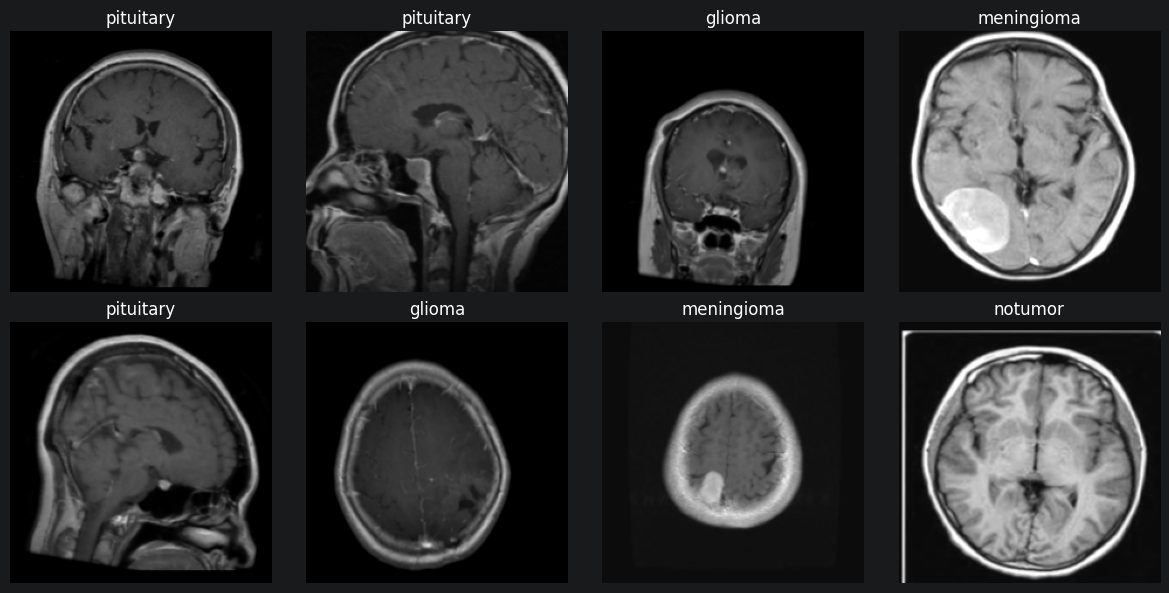

In [63]:
xb, yb = next(iter(train_ds))
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(xb[i].numpy()[..., ::-1])
    plt.title(CLASSES[int(yb[i])])
    plt.axis("off")
plt.tight_layout()
plt.show()

## 6b. Preview Augmentation
One original (left) and 4 random augmented versions of it.

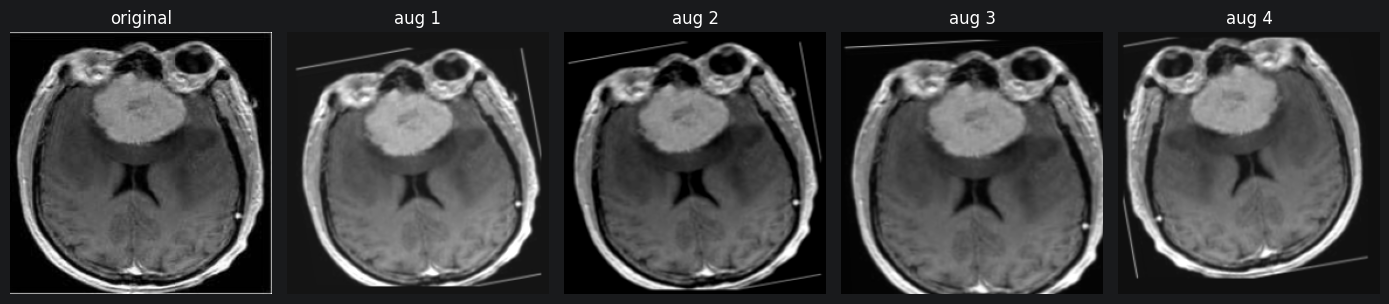

In [64]:
from src.pipeline import build_augmenter

aug = build_augmenter()
img = X[:1].astype("float32")

plt.figure(figsize=(14, 3))
plt.subplot(1, 5, 1)
plt.imshow(X[0][..., ::-1])
plt.title("original")
plt.axis("off")
for i in range(4):
    out = aug(img, training=True)[0].numpy().clip(0, 255).astype("uint8")
    plt.subplot(1, 5, i + 2)
    plt.imshow(out[..., ::-1])
    plt.title(f"aug {i + 1}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 7. Build Model

In [65]:
def conv_block(x, filters):
    x = tf.keras.layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.ReLU()(x)
    return tf.keras.layers.MaxPooling2D()(x)

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = inputs
for f in (32, 64, 128, 256):
    x = conv_block(x, f)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.4)(x)
outputs = tf.keras.layers.Dense(len(CLASSES), activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="mri_cnn")
model.summary()


Model: "mri_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_16 (ReLU)                 │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_17 (ReLU)                 │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_18 (ReLU)                 │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_19 (ReLU)                 │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 390,884 (1.49 MB)

 Trainable params: 389,924 (1.49 MB)

 Non-trainable params: 960 (3.75 KB)

## Architecture diagram

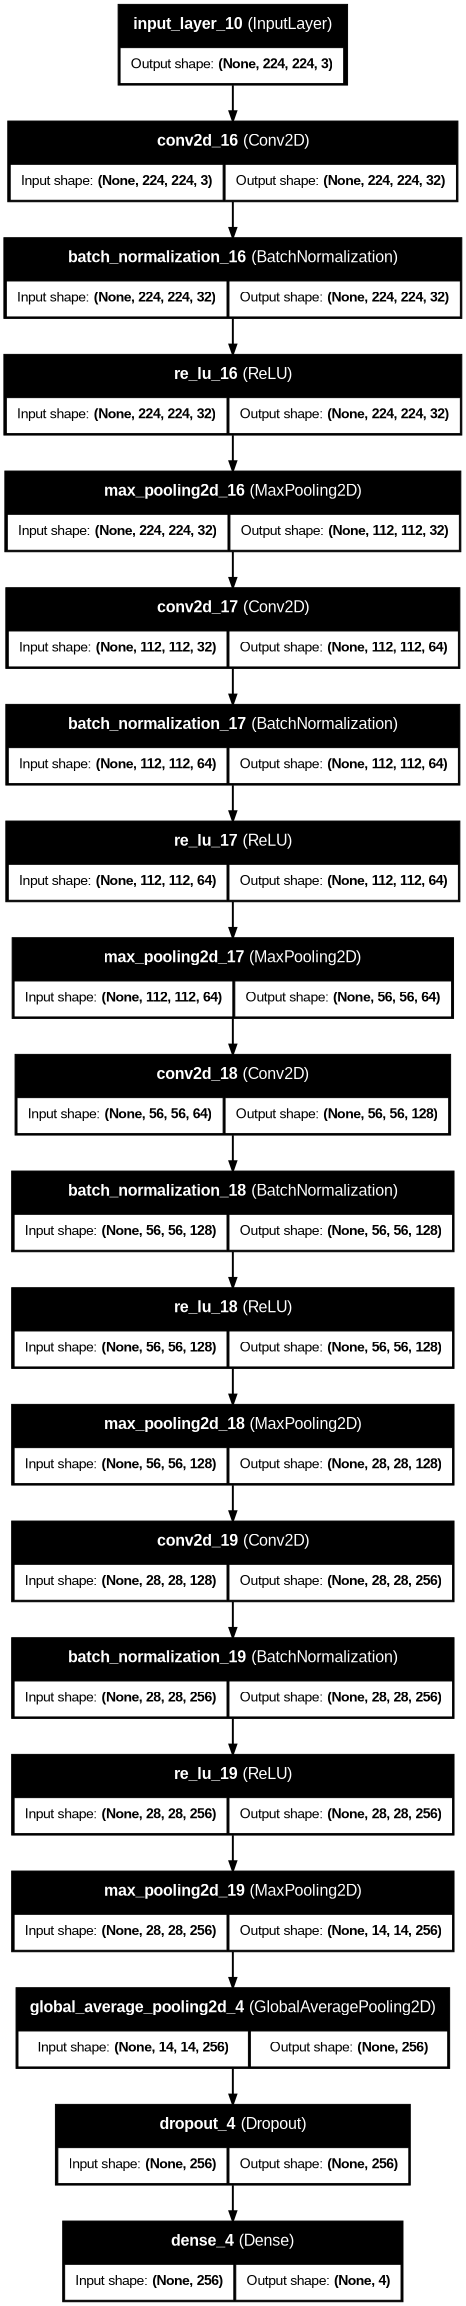

In [66]:
from IPython.display import Image, display

os.makedirs("models", exist_ok=True)

try:
    tf.keras.utils.plot_model(
        model, to_file="models/model.png",
        show_shapes=True, show_layer_names=True, dpi=70,
    )
    display(Image("models/model.png"))
except Exception as e:
    print("plot_model needs pydot + graphviz, skipping:", e)

## 8. Compile Model

In [67]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

## 9. Train

In [68]:
from src.EpochTimer import EpochTimer
import time

os.makedirs("models", exist_ok=True)


timer = EpochTimer()

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
    tf.keras.callbacks.ModelCheckpoint("models/best.keras", monitor="val_loss", save_best_only=True),
    timer,
]

start = time.perf_counter()

history = model.fit(
    train_oh,
    validation_data=val_oh,
    epochs=EPOCHS,
    class_weight=class_weight,
    callbacks=callbacks,
)

total = time.perf_counter() - start

print(f"\nTotal training time: {total:.1f} s ({total / 60:.1f} min)")
print(f"Epochs run: {len(timer.times)} | mean per epoch: {np.mean(timer.times):.1f} s "
      f"| first epoch: {timer.times[0]:.1f} s | fastest: {min(timer.times):.1f} s")

Epoch 1/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 32s 173ms/step - accuracy: 0.6256 - loss: 0.9239 - val_accuracy: 0.2460 - val_loss: 4.0343 - learning_rate: 0.0010
Epoch 2/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 23s 155ms/step - accuracy: 0.6698 - loss: 0.8001 - val_accuracy: 0.2460 - val_loss: 3.6933 - learning_rate: 0.0010
Epoch 3/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 23s 156ms/step - accuracy: 0.7074 - loss: 0.7282 - val_accuracy: 0.3451 - val_loss: 2.4599 - learning_rate: 0.0010
Epoch 4/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 23s 155ms/step - accuracy: 0.7241 - loss: 0.6970 - val_accuracy: 0.6964 - val_loss: 0.8094 - learning_rate: 0.0010
Epoch 5/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 23s 155ms/step - accuracy: 0.7483 - loss: 0.6478 - val_accuracy: 0.7702 - val_loss: 0.6547 - learning_rate: 0.0010
Epoch 6/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 23s 156ms/step - accuracy: 0.7741 - loss: 0.5974 - val_accuracy: 0.5516 - val_loss: 1.4929 - learning_rate: 0.0010
Epoch 7/20
145/145 ━━━━━━━━━━━━━━━━━━━━ 23s 158ms/step - accuracy: 0.7

KeyboardInterrupt: 

## 10. Training Curves

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, m in zip(ax, ("loss", "accuracy")):
    a.plot(history.history[m], label="train")
    a.plot(history.history[f"val_{m}"], label="val")
    a.set_title(m)
    a.set_xlabel("epoch")
    a.legend()
plt.tight_layout()
plt.show()


## 11. Evaluate

In [ ]:
val_loss, val_acc = model.evaluate(val_ds)
print(f"val loss: {val_loss:.4f} | val accuracy: {val_acc:.4f}")

## 12. Per-Class Report
val_ds is not shuffled, so predictions and labels line up.

In [ ]:
y_true = np.concatenate([yb.numpy() for _, yb in val_ds])
y_pred = np.argmax(model.predict(val_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(cmap="Blues", xticks_rotation=45)
plt.show()

## 13. Save Model

In [ ]:
model.save("models/mri_cnn.keras")
print("saved to models/mri_cnn.keras")

## 14. Final Test

In [ ]:
test_ds = get_test_ds(
    RAW_DIR, CLASSES,
    batch_size=BATCH_SIZE,
    val_split=VAL_SPLIT,
    test_split=TEST_SPLIT,
    target_size=IMG_SIZE,
    seed=SEED,
)

test_loss, test_acc = model.evaluate(test_ds)
print(f"TEST loss: {test_loss:.4f} | TEST accuracy: {test_acc:.4f}")

y_true = np.concatenate([yb.numpy() for _, yb in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=CLASSES).plot(cmap="Blues", xticks_rotation=45)
plt.show()